Shape: (15000, 36)

Columns:
['Order_ID', 'Order_Date', 'Product_Category', 'Customer_Region', 'Warehouse_Region', 'Shipping_Method', 'Delivery_Partner', 'Payment_Method', 'Order_Value', 'Order_Quantity', 'Package_Weight_KG', 'Package_Volume_CM3', 'Distance_KM', 'Warehouse_Processing_Hours', 'Traffic_Delay_Minutes', 'Weather_Delay_Minutes', 'Courier_Rating', 'Courier_Experience_Years', 'Warehouse_Capacity_Utilization', 'Inventory_Availability', 'Weekend_Flag', 'Holiday_Flag', 'Promotion_Flag', 'Estimated_Delivery_Hours', 'Promised_Delivery_Hours', 'Delivery_Delay_Hours', 'On_Time_Delivery_Flag', 'Cancellation_Flag', 'Return_Flag', 'Shipping_Cost', 'Logistics_Cost', 'Customer_Satisfaction_Score', 'Delivery_Status', 'Order_Hour', 'Day_of_Week', 'Month']

First 5 rows:
      Order_ID           Order_Date Product_Category Customer_Region  \
0  ORD00000001  2022-01-01 00:00:00           Beauty           South   
1  ORD00000002  2022-01-01 02:20:10      Electronics            East   
2  ORD0

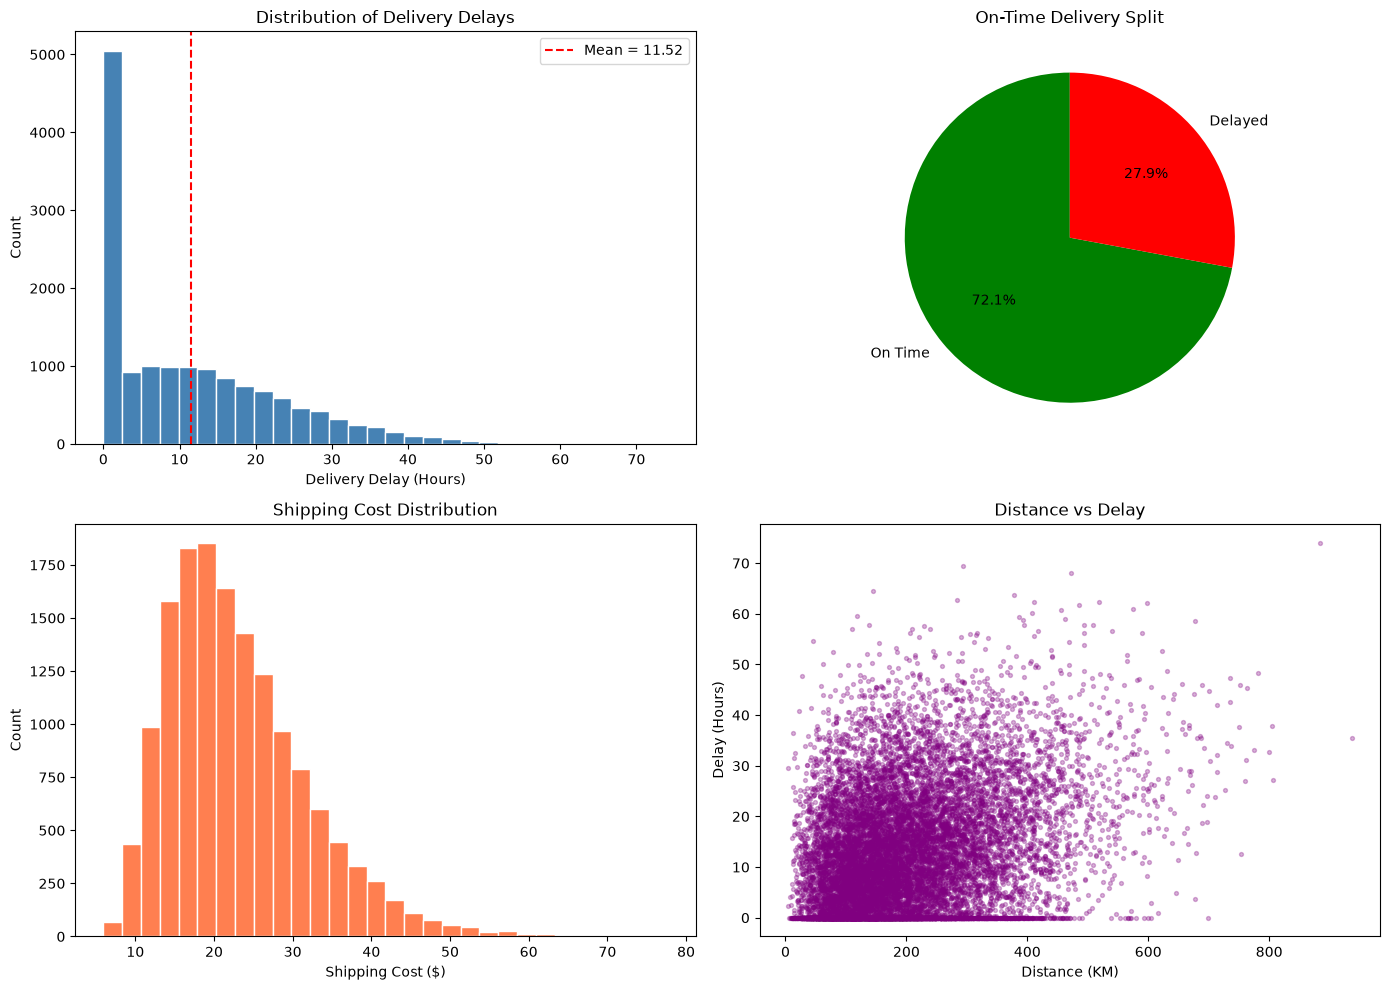

In [1]:
"""
Week 1 - Strategic Planning and Data Exploration
Logistics Data Analysis Internship
Dataset: ecommerce_logistics_delivery.csv
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('ecommerce_logistics_delivery.csv')

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nBasic statistics:")
print(df.describe())



ontime_rate = df['On_Time_Delivery_Flag'].mean() * 100
print(f"\nOn-Time Delivery Rate: {ontime_rate:.2f}%")

avg_delay = df['Delivery_Delay_Hours'].mean()
print(f"Average Delivery Delay: {avg_delay:.2f} hours")

avg_cost = df['Shipping_Cost'].mean()
print(f"Average Shipping Cost: ${avg_cost:.2f}")

avg_processing = df['Warehouse_Processing_Hours'].mean()
print(f"Average Warehouse Processing Time: {avg_processing:.2f} hours")

avg_satisfaction = df['Customer_Satisfaction_Score'].mean()
print(f"Average Customer Satisfaction: {avg_satisfaction:.2f}/5")



fig, ax = plt.subplots(2, 2, figsize=(14, 10))

ax[0, 0].hist(df['Delivery_Delay_Hours'], bins=30, color='steelblue', edgecolor='white')
ax[0, 0].axvline(avg_delay, color='red', linestyle='--', label=f'Mean = {avg_delay:.2f}')
ax[0, 0].set_xlabel('Delivery Delay (Hours)')
ax[0, 0].set_ylabel('Count')
ax[0, 0].set_title('Distribution of Delivery Delays')
ax[0, 0].legend()

counts = df['On_Time_Delivery_Flag'].value_counts()
ax[0, 1].pie(counts, labels=['On Time', 'Delayed'], autopct='%1.1f%%',
             colors=['green', 'red'], startangle=90)
ax[0, 1].set_title('On-Time Delivery Split')

ax[1, 0].hist(df['Shipping_Cost'], bins=30, color='coral', edgecolor='white')
ax[1, 0].set_xlabel('Shipping Cost ($)')
ax[1, 0].set_ylabel('Count')
ax[1, 0].set_title('Shipping Cost Distribution')

ax[1, 1].scatter(df['Distance_KM'], df['Delivery_Delay_Hours'],
                 alpha=0.3, s=8, color='purple')
ax[1, 1].set_xlabel('Distance (KM)')
ax[1, 1].set_ylabel('Delay (Hours)')
ax[1, 1].set_title('Distance vs Delay')

plt.tight_layout()
plt.savefig('week1_plots.png', dpi=150)
plt.show()
